In [2]:
import sys
import os

#####################
# Import of utils.py functions
#####################
# Required to get utils.py and access its functions
notebook_dir = os.path.abspath("")
parent_dir = os.path.abspath(os.path.join(notebook_dir, '..'))
sys.path.append(parent_dir)
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist, interactive_MCQ

####################
# DIPY_HOME should be set prior to import of dipy to make sure all downloads point to the right folder
####################
os.environ["DIPY_HOME"] = "/home/jovyan/Data"


#############################
# Loading fsl and freesurfer within Neurodesk
# You can find the list of available other modules by clicking on the "Softwares" tab on the left
#############################
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.load('freesurfer/7.4.1')
await lmod.list()

####################
# Setup FSL path
####################
loadFSL()

###################
# Load all relevant libraries for the lab
##################
import fsl.wrappers
from fsl.wrappers import fslmaths

import mne_nirs
import nilearn
from nilearn.datasets import fetch_development_fmri

import mne
import mne_nirs

import xml.etree.ElementTree as ET
import os.path as op
import nibabel as nib
import glob

!pip install antspyx
import ants

import openneuro
from mne.datasets import sample
from mne_bids import BIDSPath, read_raw_bids, print_dir_tree, make_report

# Useful imports to define the direct download function below
import requests
import urllib.request
from tqdm import tqdm


# FSL function wrappers which we will call from python directly
from fsl.wrappers import fast, bet
from fsl.wrappers.misc import fslroi
from fsl.wrappers import flirt

# General purpose imports to handle paths, files etc
import glob
import pandas as pd
import numpy as np
import json
fMRI_data_root = op.join(notebook_dir, 'fMRI', 'tfMRI_LANGUAGE_LR')
fMRI_data_filepath = op.join(fMRI_data_root, 'tfMRI_LANGUAGE_LR.nii.gz')

  Using cached scipy-1.15.3-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached scipy-1.15.3-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (37.3 MB)
  Attempting uninstall: scipy
    Found existing installation: scipy 1.18.1
    Uninstalling scipy-1.18.1:
ERROR: Could not install packages due to an OSError: [Errno 13] Permission denied: '/opt/conda/lib/python3.13/site-packages/scipy-1.18.1.dist-info/'
Consider using the `--user` option or check the permissions.



In [ ]:
%gui wx

In [ ]:
################
# Start FSLeyes (very neat tool to visualize MRI data of all sorts) within Python
################
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()

316


Text(0, 0.5, 'Mean voxel intensity')

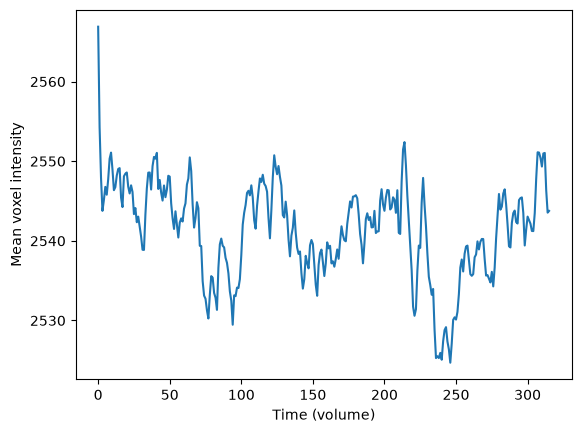

In [3]:
### Removing problematic volumes
# 1) remove first volumes, we need to see when the signal settles
import matplotlib.pyplot as plt
import nibabel as nib

fMRI_data_full = nib.load(op.join(fMRI_data_filepath)).get_fdata()
total_nb_volumes = fMRI_data_full.shape[3]
print(total_nb_volumes)
plt.plot(fMRI_data_full.mean(axis=(0,1,2)))
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')

In [4]:
## We see the first volume is a big drop, but as we did in lab 3, we will remove the first 10 to be sure.
file_to_trim = glob.glob(fMRI_data_filepath)[0]
derivatives_folder = op.join(notebook_dir, 'derivatives')
output_target = op.join(derivatives_folder, 'tfMRI_LANGUAGE_LR_settled.nii.gz')
# For this, knowing that there are originally 184 volumes and that you want to throw away the first 10, please fill in
# the following variables
start_vol = 9 # Where should we start? (First volume is 0, not 1 !)
number_of_volumes = total_nb_volumes - start_vol

In [ ]:
# Function creating new nifti with trimmed number of volumes
fslroi(file_to_trim, output_target, str(start_vol), str(number_of_volumes))
print(f"You kept {nib.load(output_target).shape[-1]} volumes.")

In [5]:
from fsl.wrappers import mcflirt

# Input: your fMRI file
fMRI_settled_data_filepath = output_target

# Output: a derivatives folder next to the data
preproc_root = op.join(notebook_dir, 'derivatives')
os.makedirs(preproc_root, exist_ok=True)

path_moco_data = op.join(preproc_root, 'tfMRI_LANGUAGE_LR_moco')

In [ ]:
mcflirt(infile=fMRI_settled_data_filepath, o=path_moco_data, plots=True, report=True, dof=6, mats=True)

In [ ]:
print_dir_tree(preproc_root, max_depth=5)

In [ ]:
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(fMRI_data_filepath)
fsleyesDisplay.load(path_moco_data)

In [7]:
def load_mot_params_fsl_6_dof(path):
    return pd.read_csv(path, sep='  ', header=None, 
            engine='python', names=['Rotation x', 'Rotation y', 'Rotation z','Translation x', 'Translation y', 'Translation z'])

mot_params = load_mot_params_fsl_6_dof(op.join(preproc_root, 'tfMRI_LANGUAGE_LR_moco.par'))
mot_params

,Rotation x,Rotation y,Rotation z,Translation x,Translation y,Translation z
0,0.000316,-0.000213,0.000144,-0.042112,-0.014714,0.032973
1,0.000008,-0.000026,0.000598,-0.031466,0.004794,-0.033811
2,-0.000041,-0.000261,0.000309,-0.032421,0.023103,-0.058697
3,0.000150,-0.000324,0.000051,-0.035766,-0.018788,0.031094
4,-0.000192,-0.000471,0.000040,-0.032432,0.012152,0.033224
...,...,...,...,...,...,...
302,0.000708,-0.000182,-0.000021,-0.031232,-0.028393,0.010999
303,0.000411,-0.000182,-0.000021,0.045673,-0.020540,0.039338
304,0.000791,-0.000337,-0.000076,-0.031231,-0.020642,0.026120
305,0.000191,-0.000182,-0.000021,-0.031232,-0.022710,0.037704


In [8]:
def compute_FD_power(mot_params):
    framewise_diff = mot_params.diff().iloc[1:]

    rot_params = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']]
    # Estimating displacement on a 50mm radius sphere
    # To know this one, we can remember the definition of the radian!
    # Indeed, let the radian be theta, the arc length be s and the radius be r.
    # Then theta = s / r
    # We want to determine here s, for a sphere of 50mm radius and knowing theta. Easy enough!
    
    # Another way to think about it is through the line integral along the circle.
    # Integrating from 0 to theta with radius 50 will give you, unsurprisingly, r0 theta.
    converted_rots = rot_params*50
    trans_params = framewise_diff[['Translation x', 'Translation y', 'Translation z']]
    fd = converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)
    return fd

fd = compute_FD_power(mot_params).to_numpy()

In [9]:
threshold = np.quantile(fd,0.75) + 1.5*(np.quantile(fd,0.75) - np.quantile(fd,0.25))

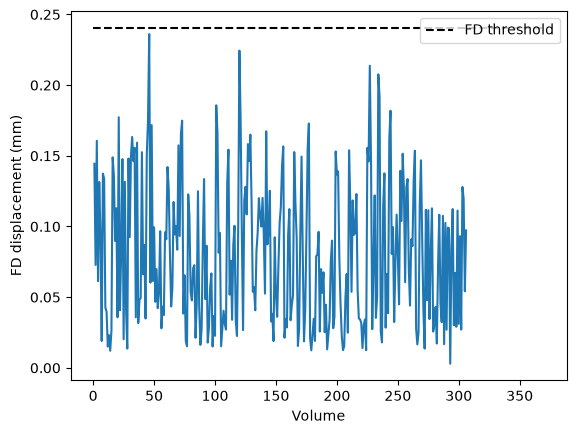

In [10]:
#%matplotlib inline
plt.plot(list(range(1, fd.size+1)), fd)
plt.xlabel('Volume')
plt.ylabel('FD displacement (mm)')
plt.hlines(threshold, 0, 370,colors='black', linestyles='dashed', label='FD threshold')
plt.legend()
plt.show()

In [ ]:
print(f"Indices of frames above threshold: {(np.where(fd > threshold)[0] + 1).tolist()}")

In [ ]:
#The patient did not have anz significant movement. The FWD is alwazs below the threshold

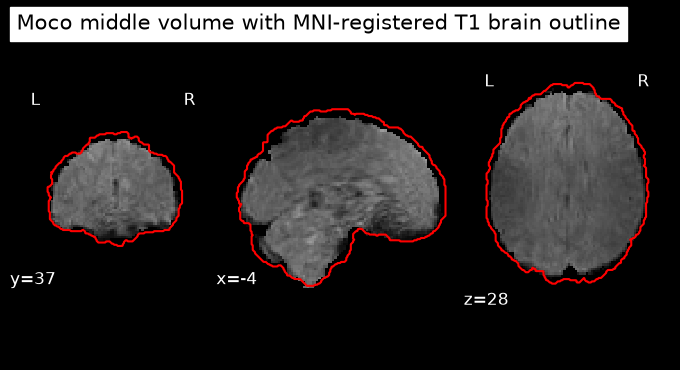

In [11]:
## NOW WE DO Registration from Functional to anatomical ## WE ACTUALLY DONT NEED, we can just moco and smoth directly.
## We justify here why : the fMRI data is already in MNI space, thus we don't need to register it to MNI space.
# Here we compare Functional to MNI-registered structural
from nilearn import image, plotting

raw_midvol = path_moco_data + '_midvol'
fslroi(path_moco_data, raw_midvol, str(number_of_volumes // 2), '1')

t1_mni = op.join(derivatives_folder, 'T1w_brain_2_mni') + '.nii.gz'
t1_brain_mask = image.math_img('(img > 0).astype(np.float32)', img=t1_mni)

display = plotting.plot_anat(raw_midvol + '.nii.gz', title='Moco middle volume with MNI-registered T1 brain outline', draw_cross=False)
display.add_contours(t1_brain_mask, levels=[0.5], colors='r')
plotting.show()

In [ ]:
## Full smooothing directly on MOCO

In [13]:
fwhm = 6
smoothed_fmri_filename = '{}_smoothed-{}mm'.format(path_moco_data, fwhm)

In [ ]:
subprocess.run(['fslmaths', path_moco_data, '-s', str(fwhm/2.3548), smoothed_fmri_filename])

In [ ]:
# Here we compare the midvolume before and after smoothing

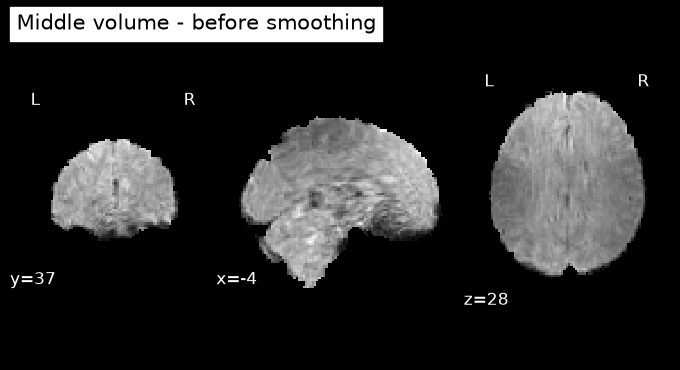

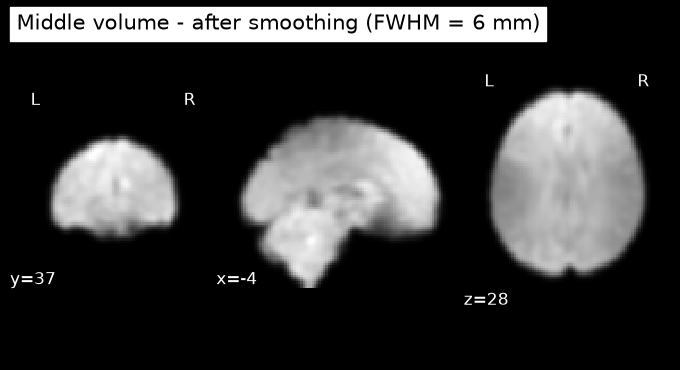

In [14]:
mid = str(number_of_volumes // 2)
raw_midvol = path_moco_data + '_midvol'
smoothed_midvol = smoothed_fmri_filename + '_midvol'
fslroi(path_moco_data, raw_midvol, mid, '1')
fslroi(smoothed_fmri_filename, smoothed_midvol, mid, '1')

display = plotting.plot_epi(raw_midvol + '.nii.gz', cmap='gray', title='Middle volume - before smoothing', draw_cross=False)
plotting.plot_epi(smoothed_midvol + '.nii.gz', cut_coords=display.cut_coords, cmap='gray',
                  title='Middle volume - after smoothing (FWHM = {} mm)'.format(fwhm), draw_cross=False)
plotting.show()

In [ ]:
# We can also add the full smoothed movie to fsleye to visualize 
fsleyesDisplay.load(smoothed_fmri_filename)

In [ ]:
### DO NOT RUN ANYTHING BELOW

In [ ]:
# We need skull stripped T1 & perform tissue segmentation for registration
import subprocess
whole_t1 = os.path.join(notebook_dir, 'T1', 'T1w.nii.gz')
skull_stripped_t1 = op.join(derivatives_folder, 'T1w_brain')
white_matter_segmentation = op.join(derivatives_folder, "T1w_fast_pve_2") # two is white matter
## use motion corrected as source for registration
epi_source = path_moco_data
output_midvol_2_anat = op.join(derivatives_folder, "tfMRI_LANGUAGE_LR_moco_midvol_2_anat")

In [ ]:
#use the middle moco volume as reference, use fslroi to extract it
ref_vol_name = op.join(derivatives_folder, "tfMRI_LANGUAGE_LR_moco_midvol")

In [ ]:
fslroi(path_moco_data, ref_vol_name, str(number_of_volumes // 2), '1')
# run the registration
subprocess.run(['epi_reg','--epi={}'.format(ref_vol_name), '--t1={}'.format(whole_t1), '--t1brain={}'.format(skull_stripped_t1), 
                '--out={}'.format(output_midvol_2_anat),
               '--wmseg={}'.format(white_matter_segmentation)])
# Now we have registered fMRI to the individual's structural, 
# but we still need to bring fMRI to MNI, to we apply the MNI matrix now

In [ ]:
## visualize alignement between MNI aligned anat and fMRI registered to anat but not to MNI
skull_stripped_t1_MNI = op.join(derivatives_folder, 'T1w_brain_2_mni')
fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(skull_stripped_t1)
fsleyesDisplay.load(skull_stripped_t1_MNI)
fsleyesDisplay.load(output_midvol_2_anat)

In [ ]:
# apply MNI matrix
func_2_anat_mat = output_midvol_2_anat + '.mat'                         # epi_reg: func -> T1
anat_2_mni_mat  = op.join(derivatives_folder, 'T1w_brain_2_mni.mat')   # flirt:   T1   -> MNI
mni_template    = op.expandvars(op.join('$FSLDIR', 'data', 'standard', 'MNI152_T1_1mm_brain'))
func_2_mni_mat  = op.join(derivatives_folder, 'tfMRI_LANGUAGE_LR_moco_2_mni.mat')
midvol_mni      = op.join(derivatives_folder, 'tfMRI_LANGUAGE_LR_moco_midvol_2_mni')

In [ ]:
subprocess.run(['convert_xfm', '-omat', func_2_mni_mat,
                '-concat', anat_2_mni_mat, func_2_anat_mat])
subprocess.run(['flirt', '-in', ref_vol_name, '-ref', mni_template,
                '-applyxfm', '-init', func_2_mni_mat, '-out', midvol_mni])

In [ ]:
#fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(op.join(derivatives_folder, 'T1w_brain_2_mni'))   # T1w_brain_2_mni        # T1w_brain_2_mni
fsleyesDisplay.load(midvol_mni)

In [ ]:
## now we do smoothing on the MNI aligned, but how to choose fwhm ?

In [ ]:
fwhm = 6
smoothed_fmri_filename = '{}_smoothed-{}mm'.format(midvol_mni, fwhm)
subprocess.run(['fslmaths', midvol_mni, '-s', str(fwhm/2.3548), smoothed_fmri_filename])

In [ ]:
## visualize smoothed brain midvolume fmri

In [ ]:
fsleyesDisplay.load(smoothed_fmri_filename)

In [ ]:
## now we can apply MNI matrix and then smoothing to the entire 4D series and save